# Non-NN ball tracking
DoG blob candidates → HOG + colour + motion features → SVM cascade → static-ball penalty → Kalman filter.
Shared code (data loading, tracker, evaluation) is in `common.py`.

In [1]:
import os, time, pickle, json
import numpy as np, cv2, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import LinearSVC, SVC
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from joblib import Parallel, delayed
from common import *

OUT, CACHE = 'results/non_nn', 'cache/non_nn'
TRAIN_STEP = 8
os.makedirs(OUT, exist_ok=True)
os.makedirs(CACHE, exist_ok=True)
rng = np.random.default_rng(0)

train_seqs, val_seqs = load_soccernet()
print(len(train_seqs), 'train seqs,', len(val_seqs), 'val seqs')

86 train seqs, 20 val seqs


## Candidates: field mask + DoG blobs

In [2]:
P = 16  # patch size

def field_mask(im):
    g = cv2.inRange(cv2.cvtColor(im, cv2.COLOR_BGR2HSV), (30, 40, 40), (90, 255, 255))
    g = cv2.morphologyEx(g, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(g)
    m = np.zeros_like(g)
    if n < 2:
        return m
    k = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])
    cnt, _ = cv2.findContours((lab == k).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.fillPoly(m, [cv2.convexHull(np.vstack(cnt))], 255)
    return cv2.dilate(m, np.ones((21, 21), np.uint8))

def candidates(im, t=10, er=10, s1=1.0, s2=2.5):
    g = im.min(2).astype(np.float32)  # whiteness
    a = cv2.GaussianBlur(g, (0, 0), s1)
    d = a - cv2.GaussianBlur(g, (0, 0), s2)  # DoG
    pk = (d == cv2.dilate(d, np.ones((3, 3), np.uint8))) & (d > t) & (field_mask(im) > 0)
    pk[:P] = pk[-P:] = False
    pk[:, :P] = pk[:, -P:] = False
    dxx = cv2.Sobel(a, cv2.CV_32F, 2, 0, ksize=3)
    dyy = cv2.Sobel(a, cv2.CV_32F, 0, 2, ksize=3)
    dxy = cv2.Sobel(a, cv2.CV_32F, 1, 1, ksize=3)
    tr, det = dxx + dyy, dxx * dyy - dxy ** 2
    pk &= (det > 0) & (tr ** 2 < det * (er + 1) ** 2 / er)  # edge test
    ys, xs = np.nonzero(pk)
    return np.stack([xs, ys], 1), np.stack([d[ys, xs], tr[ys, xs] ** 2 / (det[ys, xs] + 1e-6)], 1)

candidate recall 0.844, 450 candidates/frame


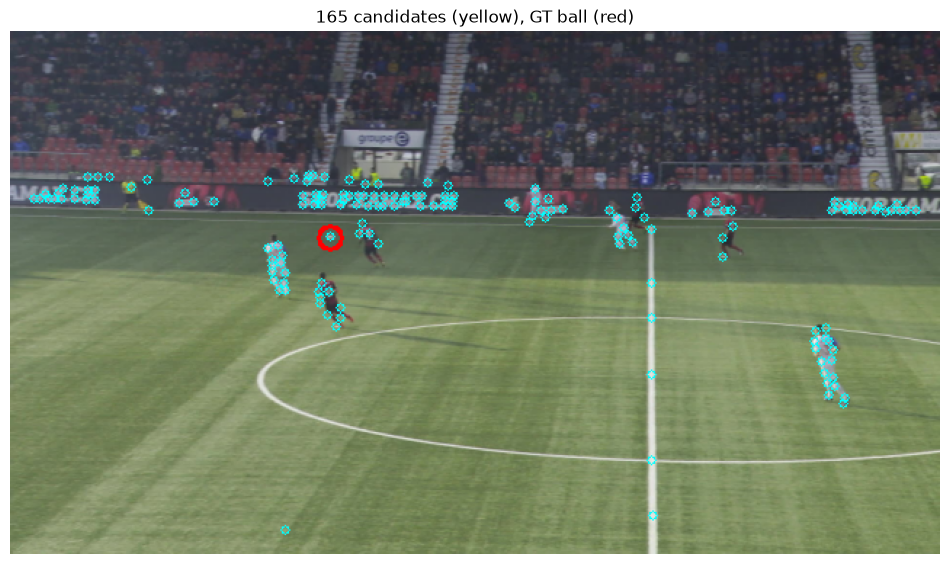

In [3]:
s, f = val_seqs[0], 300
im = read_frame(s, f)
xy, _ = candidates(im)
vis = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
for x, y in xy:
    cv2.circle(vis, (int(x), int(y)), 3, (0, 255, 255), 1)
if f in s['ball']:
    bx, by = center(s['ball'][f])
    cv2.circle(vis, (int(bx), int(by)), 8, (255, 0, 0), 2)
plt.figure(figsize=(12, 7))
plt.imshow(vis)
plt.title(f'{len(xy)} candidates (yellow), GT ball (red)')
plt.axis('off')

hit, n = [], []
for s in val_seqs:
    for f in range(1, s['n'] + 1, 25):
        if f in s['ball']:
            xy, _ = candidates(read_frame(s, f))
            n.append(len(xy))
            hit.append(len(xy) > 0 and np.hypot(*(xy - center(s['ball'][f])).T).min() <= 4)
print(f'candidate recall {np.mean(hit):.3f}, {np.mean(n):.0f} candidates/frame')

## Features: HOG + colour + motion

In [4]:
CELL, NB = 4, 9

def cell_hist(gray):
    g = gray.astype(np.float32)
    gx = cv2.filter2D(g, -1, np.array([[-1, 0, 1]], np.float32))
    gy = cv2.filter2D(g, -1, np.array([[-1], [0], [1]], np.float32))
    mag = np.hypot(gx, gy)
    b = np.minimum((np.rad2deg(np.arctan2(gy, gx)) % 180 / (180 / NB)).astype(int), NB - 1)
    hist = np.zeros(g.shape + (NB,), np.float32)
    np.put_along_axis(hist, b[..., None], mag[..., None], 2)
    I = np.pad(hist.cumsum(0).cumsum(1), ((1, 0), (1, 0), (0, 0)))  # integral image
    return I[CELL:, CELL:] - I[:-CELL, CELL:] - I[CELL:, :-CELL] + I[:-CELL, :-CELL]

def hog(C, xy):
    n = P // CELL
    x0, y0 = xy[:, 0].astype(int) - P // 2, xy[:, 1].astype(int) - P // 2
    o = np.arange(n) * CELL
    cells = C[y0[:, None, None] + o[None, :, None], x0[:, None, None] + o[None, None, :]]
    blk = np.stack([cells[:, j:j + 2, i:i + 2].reshape(len(xy), -1) for j in range(n - 1) for i in range(n - 1)], 1)
    blk = blk / np.sqrt((blk ** 2).sum(2, keepdims=True) + 1e-2)  # L2 norm
    return blk.reshape(len(xy), -1)

def patch(img, xy, r):
    k = np.arange(-r, r + 1)
    xs, ys = xy[:, 0].astype(int), xy[:, 1].astype(int)
    return img[ys[:, None, None] + k[None, :, None], xs[:, None, None] + k[None, None, :]].reshape(len(xy), (2 * r + 1) ** 2, -1)

def colour(im, xy):
    c = patch(im.astype(np.float32), xy, 1).mean(1)
    h = patch(cv2.cvtColor(im, cv2.COLOR_BGR2HSV).astype(np.float32), xy, 1).mean(1)
    rr = np.array([(-6, -6), (-6, 0), (-6, 6), (0, -6), (0, 6), (6, -6), (6, 0), (6, 6)])
    xs, ys = xy[:, 0].astype(int), xy[:, 1].astype(int)
    ring = im.astype(np.float32)[ys[:, None] + rr[None, :, 0], xs[:, None] + rr[None, :, 1]].mean(1)
    return np.hstack([c, h, ring, c - ring, c.std(1, keepdims=True), c.min(1, keepdims=True), c.max(1, keepdims=True)])

def stabilised_diff(prev, cur):
    g0, g1 = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY), cv2.cvtColor(cur, cv2.COLOR_BGR2GRAY)
    p0 = cv2.goodFeaturesToTrack(g0, 300, 0.01, 8)  # corners
    M = None
    if p0 is not None and len(p0) >= 6:
        p1, st, _ = cv2.calcOpticalFlowPyrLK(g0, g1, p0, None, winSize=(21, 21), maxLevel=3)  # LK flow
        ok = st.ravel() == 1
        if ok.sum() >= 6:
            M, _ = cv2.estimateAffinePartial2D(p0[ok], p1[ok], method=cv2.RANSAC, ransacReprojThreshold=2.0)
    if M is None:
        M = np.eye(2, 3)
    w = cv2.warpAffine(prev.min(2), M, (W, H), borderMode=cv2.BORDER_REPLICATE)
    return cv2.absdiff(cur.min(2), w).astype(np.float32)

def motion(D, xy):
    p = patch(D, xy, 1)[..., 0]
    return np.stack([p.mean(1), p.max(1)], 1)

NF = 324 + 15 + 2 + 4

def frame_features(im, p1, p2):
    xy, blob = candidates(im)
    if len(xy) == 0:
        return xy, np.zeros((0, NF), np.float32)
    h = hog(cell_hist(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), xy)
    m1, m2 = motion(stabilised_diff(p1, im), xy), motion(stabilised_diff(p2, im), xy)
    return xy, np.hstack([h, colour(im, xy), blob, m1, m2]).astype(np.float32)

## Training set (games 4, 6, 7, 8, 11) and validation frames (game 9)

In [5]:
def build_seq(s, step, nneg=40):
    r, X, y = np.random.default_rng(int(s['name'][-3:])), [], []
    for f in range(3, s['n'] + 1, step):
        xy, F = frame_features(read_frame(s, f), read_frame(s, f - 1), read_frame(s, f - 2))
        if len(xy) == 0:
            continue
        b = s['ball'].get(f)
        d = np.hypot(*(xy - center(b)).T) if b is not None else np.full(len(xy), 1e9)
        pos, neg = np.nonzero(d <= 3)[0], np.nonzero(d > 8)[0]
        neg = r.choice(neg, min(nneg, len(neg)), replace=False)
        X.append(F[np.r_[pos, neg]])
        y.append(np.r_[np.ones(len(pos)), np.zeros(len(neg))])
    return np.vstack(X), np.concatenate(y)

def val_seq(s, step=25):
    out = []
    for f in range(3, s['n'] + 1, step):
        b = s['ball'].get(f)
        out.append((None if b is None else center(b),) + frame_features(read_frame(s, f), read_frame(s, f - 1), read_frame(s, f - 2)))
    return out

def build_train():
    out = Parallel(n_jobs=-1)(delayed(build_seq)(s, TRAIN_STEP) for s in train_seqs)
    return np.vstack([o[0] for o in out]), np.concatenate([o[1] for o in out])

t0 = time.time()
X, y = cached(f'{CACHE}/train_5games.pkl', build_train)
V = cached(f'{CACHE}/val.pkl', lambda: sum(Parallel(n_jobs=-1)(delayed(val_seq)(s) for s in val_seqs), []))
print(X.shape, int(y.sum()), 'positives', f'{time.time() - t0:.0f}s')

(329625, 345) 6275 positives 3s


## SVM training and model selection

In [6]:
def rank_eval(fn, V, r=4):
    top1, top5 = [], []
    for b, xy, F in V:
        if b is None or len(xy) == 0:
            continue
        d = np.hypot(*(xy[np.argsort(-fn(F))] - b).T)
        top1.append(d[0] <= r)
        top5.append((d[:5] <= r).any())
    return np.mean(top1), np.mean(top5)

res = []
for C in [0.001, 0.01]:
    t0 = time.time()
    m = make_pipeline(StandardScaler(), LinearSVC(C=C, class_weight='balanced', dual=False)).fit(X, y)
    res.append(('linear', C, *rank_eval(m.decision_function, V), time.time() - t0, m))

idx = np.r_[np.nonzero(y == 1)[0], rng.choice(np.nonzero(y == 0)[0], 40000, replace=False)]  # all pos, 40k neg
t0 = time.time()
rbf = make_pipeline(StandardScaler(), PCA(0.95), SVC(C=1, gamma='scale', class_weight='balanced')).fit(X[idx], y[idx])
res.append(('rbf+pca', 1, *rank_eval(rbf.decision_function, V), time.time() - t0, rbf))
pd.DataFrame([r[:5] for r in res], columns=['kernel', 'C', 'top1', 'top5', 'sec'])

,kernel,C,top1,top5,sec
0,linear,0.001,0.519573,0.702847,59.310225
1,linear,0.010,0.505338,0.697509,126.123395
2,rbf+pca,1.000,0.564057,0.750890,404.619718


Cascade: the best linear SVM keeps the top-K candidates, the RBF SVM scores them.

In [7]:
lin = max(res[:2], key=lambda r: r[2])[-1]
K = 30

def cascade(F):
    s = np.full(len(F), -10.0)
    o = np.argsort(-lin.decision_function(F))[:K]
    s[o] = rbf.decision_function(F[o])
    return s

def score(xy, F):
    if len(xy) == 0:
        return np.zeros((0, 2)), np.zeros(0)
    o = np.argsort(-lin.decision_function(F))[:K]
    return xy[o].astype(float), rbf.decision_function(F[o])

def score_frames(frames, cuts=None):
    out, p1, p2 = [], None, None
    for f, im in enumerate(frames):
        if cuts is not None and cuts[f]:
            p1 = p2 = None
        out.append(score(*frame_features(im, p1, p2)) if p2 is not None else (np.zeros((0, 2)), np.zeros(0)))
        p2, p1 = p1, im
    return out

print('cascade top1/top5:', rank_eval(cascade, V))
pickle.dump(dict(lin=lin, rbf=rbf, K=K), open(f'{OUT}/svm_cascade.pkl', 'wb'))

cascade top1/top5: (np.float64(0.5587188612099644), np.float64(0.7384341637010676))


## Validation: tracking

In [8]:
VAL_TRACK = val_seqs[::3]
names = [s['name'] for s in VAL_TRACK]
val_scores = cached(f'{CACHE}/val_scores_5games.pkl', lambda: dict(zip(names, Parallel(n_jobs=-1)(
    delayed(lambda s: score_frames(read_frame(s, f) for f in range(1, s['n'] + 1)))(s) for s in VAL_TRACK))))
val_H = cached(f'{CACHE}/val_H.pkl', lambda: dict(zip(names, Parallel(n_jobs=-1)(delayed(seq_homographies)(s) for s in VAL_TRACK))))
val_gt = {s['name']: {f - 1: center(b) for f, b in s['ball'].items()} for s in VAL_TRACK}

grid = []
for ti in [0.5, 1.0, 1.5]:
    for tk in [-0.5, 0.0]:
        kw = dict(t_init=ti, t_keep=tk, t_switch=ti + 1.0, margin=1.5)
        grid.append(dict(**kw, **evaluate(lambda sc: run_tracker(sc, **kw), val_scores, val_gt)))
grid = pd.DataFrame(grid).sort_values('F1', ascending=False)
grid.head()

,t_init,t_keep,t_switch,margin,precision,recall,F1,err_px
2,1.0,-0.5,2.0,1.5,0.624488,0.633630,0.629026,1.479273
4,1.5,-0.5,2.5,1.5,0.657427,0.600593,0.627727,1.504551
3,1.0,0.0,2.0,1.5,0.621073,0.629674,0.625344,1.481352
5,1.5,0.0,2.5,1.5,0.643776,0.584174,0.612529,1.486622
1,0.5,0.0,1.5,1.5,0.603846,0.621167,0.612384,1.498347


Static-ball penalty: a candidate at the same pitch position (after removing camera motion with a homography) as a confident candidate `SK` frames earlier gets `c` subtracted. `c` is chosen on validation.

In [9]:
TRK = grid.iloc[0][['t_init', 't_keep', 't_switch', 'margin']].to_dict()

def penalise(scores, Hs, c):
    return [(xy, sc - c * m) for (xy, sc), m in zip(scores, static_mask(scores, Hs, TRK['t_init']))]

pens = pd.DataFrame([dict(c=c, **evaluate(lambda sc: run_tracker(sc, **TRK), {n: penalise(val_scores[n], val_H[n], c) for n in names}, val_gt))
                     for c in [0.0, 0.5, 1.0]])
best = pens.loc[pens.F1.idxmax()]
C_STAT = best.c
display(pens)

det = pd.DataFrame([dict(t=t, **evaluate(lambda sc: detect_only(sc, t), val_scores, val_gt)) for t in [0.5, 1.0, 1.5]])
det = det.sort_values('F1', ascending=False)
json.dump(dict(**TRK, c_static=C_STAT), open(f'{OUT}/tracker_params.json', 'w'))
pd.DataFrame([dict(method='detection only (best t)', **det.iloc[0].drop('t').to_dict()),
              dict(method='detection + Kalman', **pens.iloc[0].drop('c').to_dict()),
              dict(method=f'detection + Kalman + static penalty ({C_STAT})', **best.drop('c').to_dict())])

,c,precision,recall,F1,err_px
0,0.0,0.624488,0.633630,0.629026,1.479273
1,0.5,0.631168,0.640158,0.635632,1.479390
2,1.0,0.608865,0.616815,0.612814,1.509666


,method,precision,recall,F1,err_px
0,detection only (best t),0.661446,0.501286,0.570335,1.491179
1,detection + Kalman,0.624488,0.633630,0.629026,1.479273
2,detection + Kalman + static penalty (0.5),0.631168,0.640158,0.635632,1.479390


## Test clip: Denmark vs Wales

1500 frames, 27 cuts
186s, ball reported in 1363/1500 frames


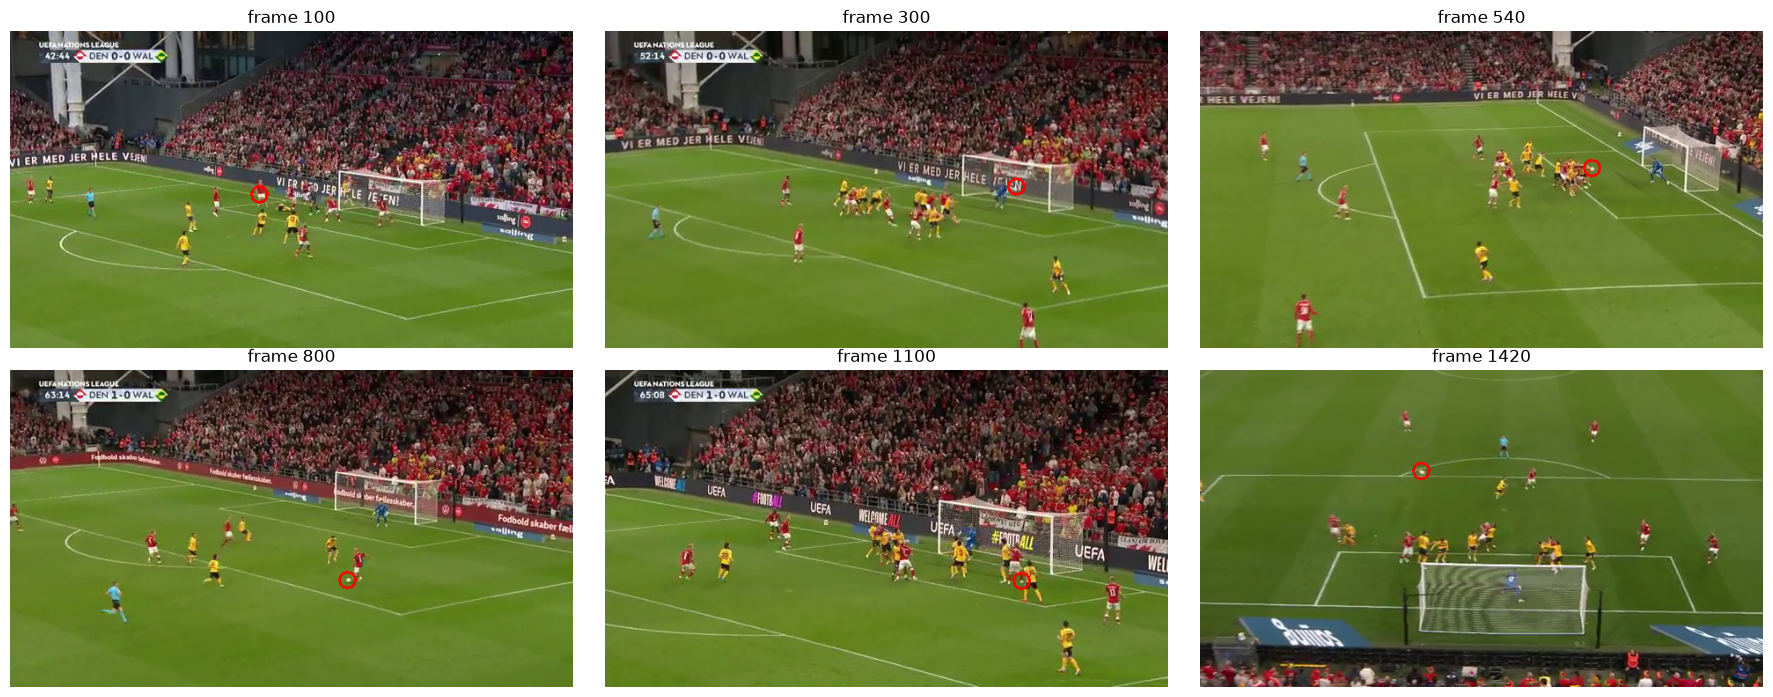

In [10]:
test_frames, fps = read_video()
cuts = [False] + [shot_cut(a, b) for a, b in zip(test_frames[:-1], test_frames[1:])]
print(len(test_frames), 'frames,', sum(cuts), 'cuts')
t0 = time.time()
test_scores = score_frames(test_frames, cuts)
test_H = homographies([cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in test_frames], cuts)
pred_plain = run_tracker(test_scores, cuts, **TRK)
pred = run_tracker(penalise(test_scores, test_H, C_STAT), cuts, **TRK)
print(f'{time.time() - t0:.0f}s, ball reported in {len(pred)}/{len(test_frames)} frames')
save_predictions(pred, len(test_frames), f'{OUT}/test_predictions.csv')
write_video(test_frames, pred, cuts, fps, f'{OUT}/test_tracking.mp4')
show_frames(test_frames, pred)

## Test evaluation

In [11]:
gt, labelled = load_gt()
test_res = pd.DataFrame([dict(method='detection only', **metrics(detect_only(test_scores, det.iloc[0].t), gt, labelled)),
                         dict(method='detection + Kalman', **metrics(pred_plain, gt, labelled)),
                         dict(method='detection + Kalman + static penalty', **metrics(pred, gt, labelled))])
test_res.to_csv(f'{OUT}/test_metrics.csv', index=False)
test_res

,method,precision,recall,F1,err_px
0,detection only,0.415323,0.461883,0.437367,1.730157
1,detection + Kalman,0.498141,0.600897,0.544715,1.682382
2,detection + Kalman + static penalty,0.516729,0.623318,0.565041,1.689257
